# Example of the aitlas toolbox in the context of multi label image classification

The SSL4EO-S12-ML dataset is multimodal: Sentinel-2 L2A, Sentinel-2 L1C and Sentinel-1 images. The Sentinel-2 L1C images were used for labeling. 

Note: for simplicity the dataloader returns either S1, S2 L1C or S2 L2A individually if the imagery parameter is set to "S1", "S2 L1C", "S2 L2A" respectively. The dataloader returns both S1 and S2 L2A if imagery is set to "all". 

## Import the required packages

In [ ]:
from aitlas.datasets import SSL4EOS12MLDataset
from aitlas.models import ResNet50MultiLabel
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [6]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/ssl4eo_s12_ml/",
    "label_file": "/home/dragik/data/FAIR_EO/ssl4eo_s12_ml/ssl4eo_multilabel.json",
    "imagery": "all",
    "selection": "rgb"
}
dataset = SSL4EOS12MLDataset(dataset_config)
print(f'Total number of image patches: {len(dataset)}')

Total number of image patches: 780371


## Show images from the dataset

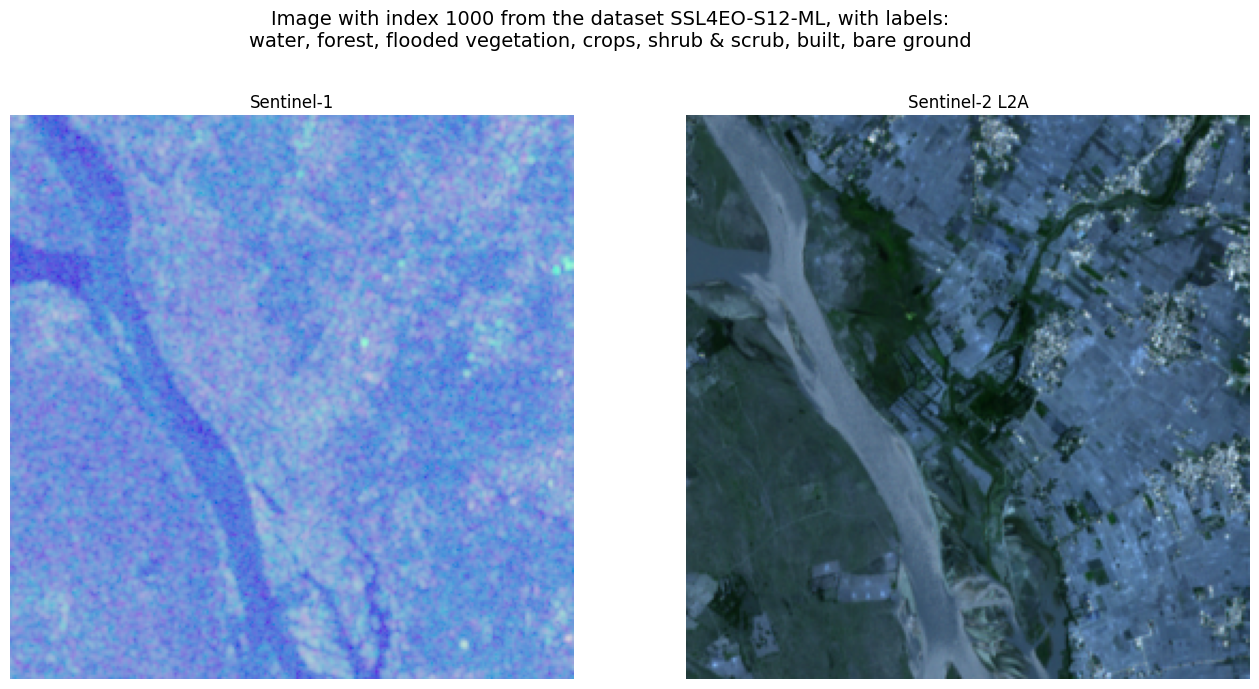

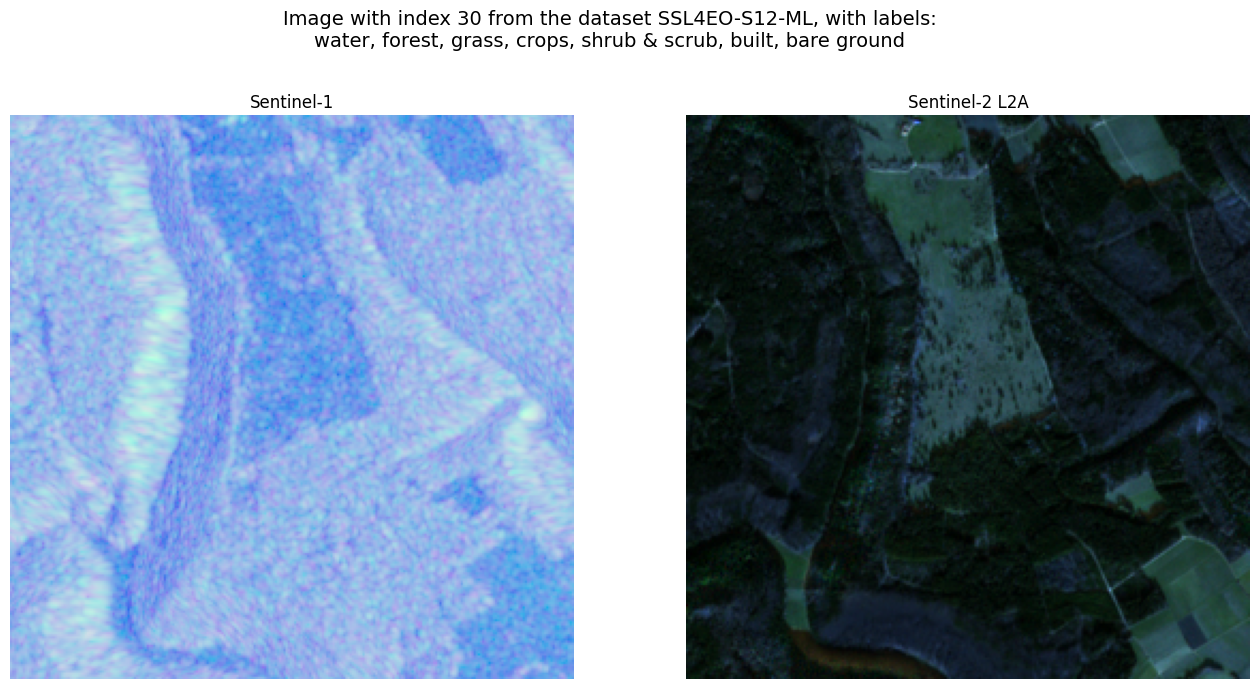

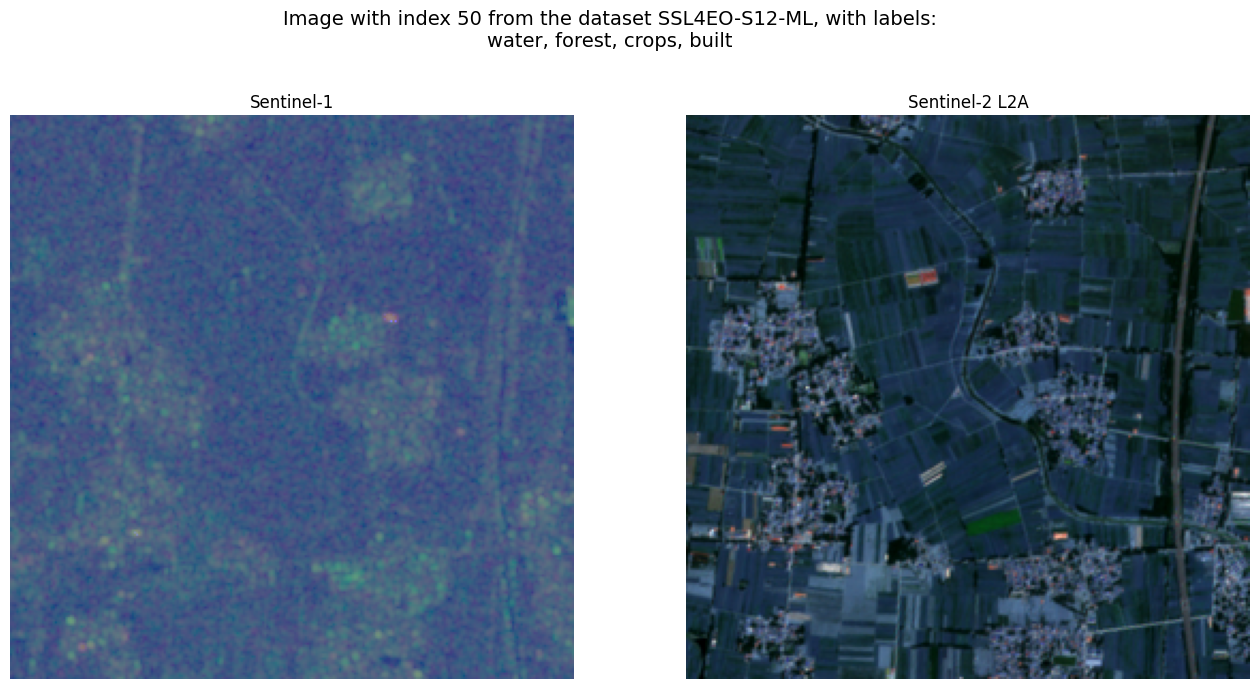

In [7]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(30)
fig3 = dataset.show_image(50)

Since the Sentinel-2 L1C images were labeled, we consider this imagery source for the remaining of the notebook.

In [38]:
# specific bands
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/ssl4eo_s12_ml/",
    "label_file": "/home/dragik/data/FAIR_EO/ssl4eo_s12_ml/ssl4eo_multilabel.json",
    "imagery": "S2 L1C",
    "selection": "bands",
    "bands_s2": ["B01","B02","B03","B04","B05","B06"]
}
dataset = SSL4EOS12MLDataset(dataset_config)

In [39]:
# rgb
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/ssl4eo_s12_ml/",
    "label_file": "/home/dragik/data/FAIR_EO/ssl4eo_s12_ml/ssl4eo_multilabel.json",
    "imagery": "S2 L1C",
    "selection": "rgb"
}
dataset = SSL4EOS12MLDataset(dataset_config)

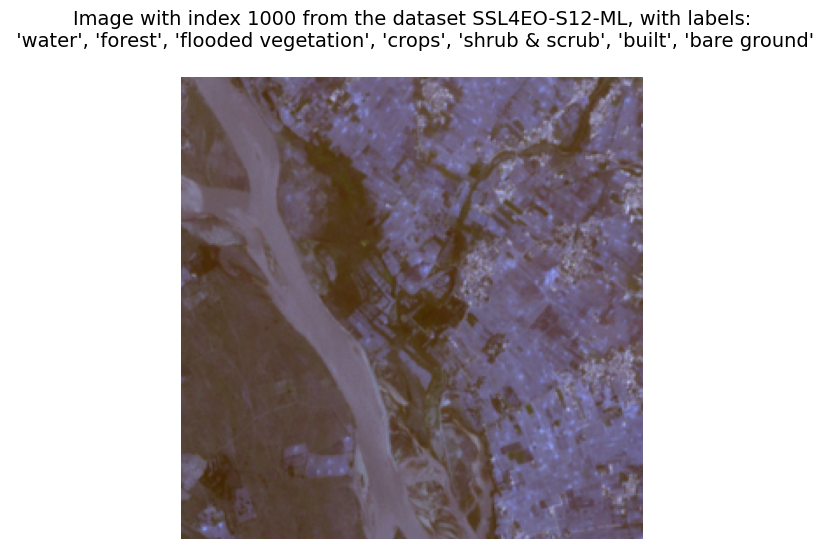

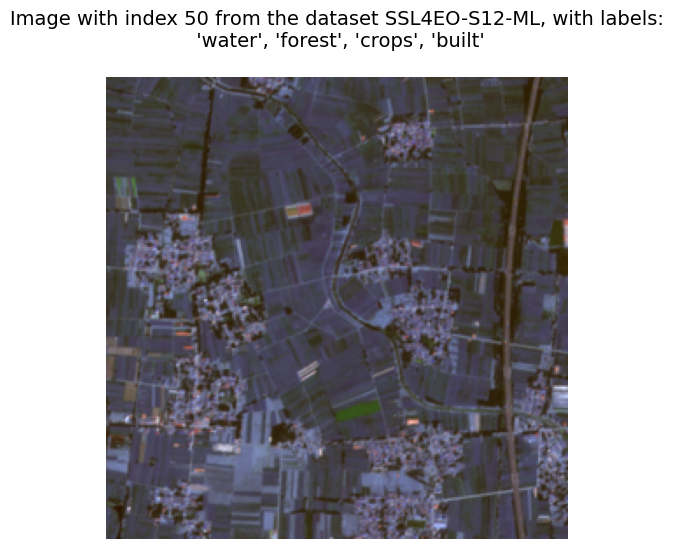

In [40]:
fig1 = dataset.show_image(1000)
fig3 = dataset.show_image(50)

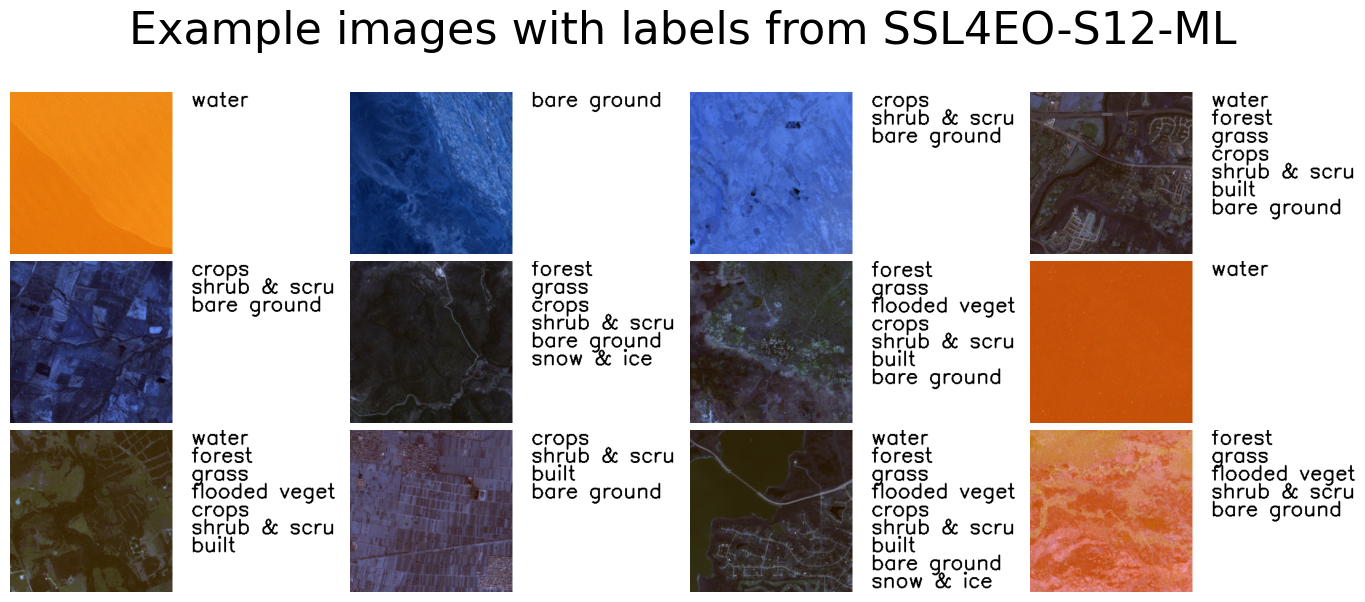

In [25]:
fig4 = dataset.show_batch(12)

## Inspect the data

In [26]:
dataset.show_samples()

,file name,labels
0,0000000/20200328T162829_20200328T164812_T15QXA,"[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]"
1,0000000/20200621T162901_20200621T164746_T15QXA,"[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]"
2,0000000/20200924T162929_20200924T164434_T15QXA,"[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]"
3,0000000/20201228T163711_20201228T164519_T15QXA,"[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]"
4,0000001/20201104T135121_20201104T135117_T21KXT,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.0]"
5,0000001/20210123T135111_20210123T135113_T21KXT,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.0]"
6,0000001/20210508T135109_20210508T135519_T21KXT,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0]"
7,0000001/20210811T135121_20210811T135115_T21KXT,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0]"
8,0000002/20210117T104259_20210117T104300_T31TFJ,"[1.0, 1.0, 1.0, 0.0, 1.0, 1.0, 1.0, 0.0, 1.0]"
9,0000002/20210402T104021_20210402T104258_T31TFJ,"[0.0, 1.0, 1.0, 0.0, 1.0, 1.0, 1.0, 0.0, 1.0]"


In [27]:
dataset.data_distribution_table()

,Label,Count
0,water,444165
1,forest,525442
2,grass,433254
3,flooded vegetation,139499
4,crops,581114
5,shrub & scrub,566198
6,built,503013
7,bare ground,525258
8,snow & ice,122574


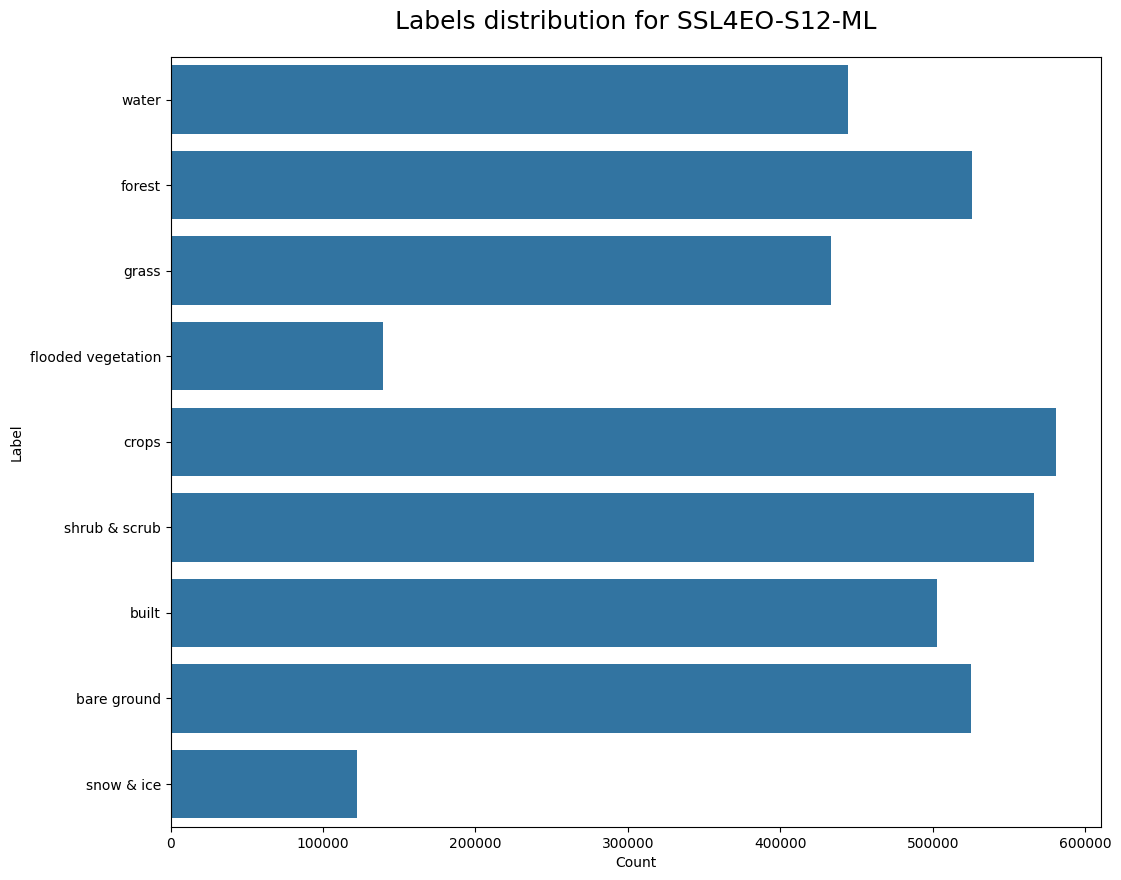

In [195]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [28]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/ssl4eo_s12_ml/",
    "label_file": "/home/dragik/data/FAIR_EO/ssl4eo_s12_ml/ssl4eo_multilabel.json",
    "imagery": "S2 L1C",
    "selection": "rgb",
    "csv_file": "/home/dragik/data/FAIR_EO/ssl4eo_s12_ml/ssl4eo_s12_ml_train.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

train_dataset = SSL4EOS12MLDataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor() 

test_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/ssl4eo_s12_ml/",
    "label_file": "/home/dragik/data/FAIR_EO/ssl4eo_s12_ml/ssl4eo_multilabel.json",
    "imagery": "S2 L1C",
    "selection": "rgb",
    "csv_file": "/home/dragik/data/FAIR_EO/ssl4eo_s12_ml/ssl4eo_s12_ml_val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = SSL4EOS12MLDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(468808, 155670)

## Setup and create the model for training

In [54]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/ssl4eo_s12_ml/"
model_config = {
    "num_classes": 9, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5, 
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = ResNet50MultiLabel(model_config)
model.prepare()

## Training and evaluation

In [201]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id='1',
)

2025-12-01 12:44:14,563 INFO Starting training.
training: 100%|██████████| 14651/14651 [22:39<00:00, 10.77it/s]
2025-12-01 13:06:54,452 INFO epoch: 1, time: 1360, loss:  0.25124
testing on train set: 100%|██████████| 14651/14651 [12:10<00:00, 20.05it/s]
2025-12-01 13:19:05,875 INFO Accuracy:0.9019446956726184, Accuracy per Class:[0.83337102 0.94287427 0.90776608 0.86384191 0.94130433 0.92606781
 0.92282555 0.87117754 0.90827375], Precision Micro:0.9109119854761999, Precision Macro:0.8816740437618483, Precision Weighted:0.9078954416261551, Precision per Class:[0.85507443 0.94674898 0.91815204 0.65866577 0.95484128 0.9265744
 0.94493973 0.87634708 0.85372267], Recall Micro:0.9096915011030353, Recall Macro:0.838866523853643, Recall Weighted:0.9096915011030353, Recall per Class:[0.85133863 0.96969726 0.91564979 0.49199766 0.96694906 0.97548616
 0.93473952 0.94153816 0.50240248], F1_score Micro:0.9103013341994126, F1_score Macro:0.8536498215146243, F1_score Weighted:0.9066215480334394, F1_s

0.18361363696343366

## Predictions

2025-12-02 07:51:37,491 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/ssl4eo_s12_ml/checkpoint.pth.tar
2025-12-02 07:51:37,663 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/ssl4eo_s12_ml/checkpoint.pth.tar at epoch 11


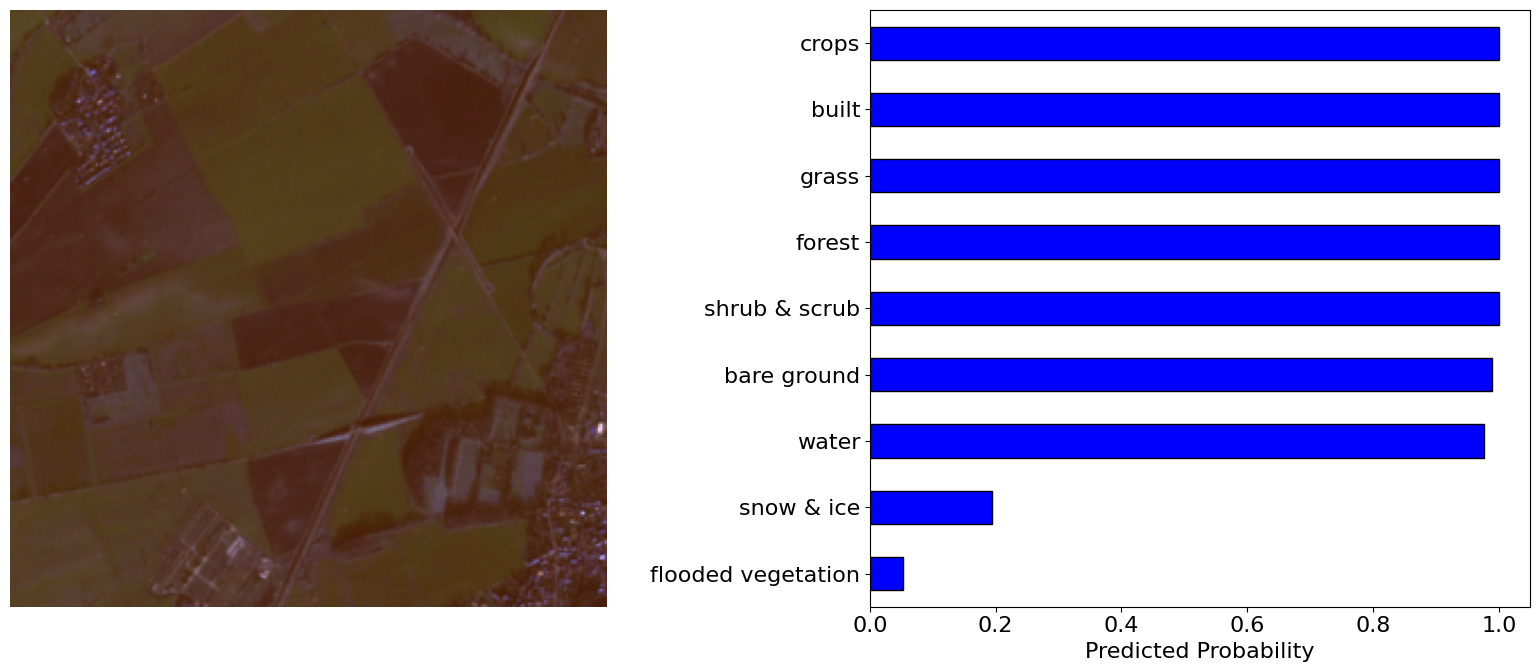

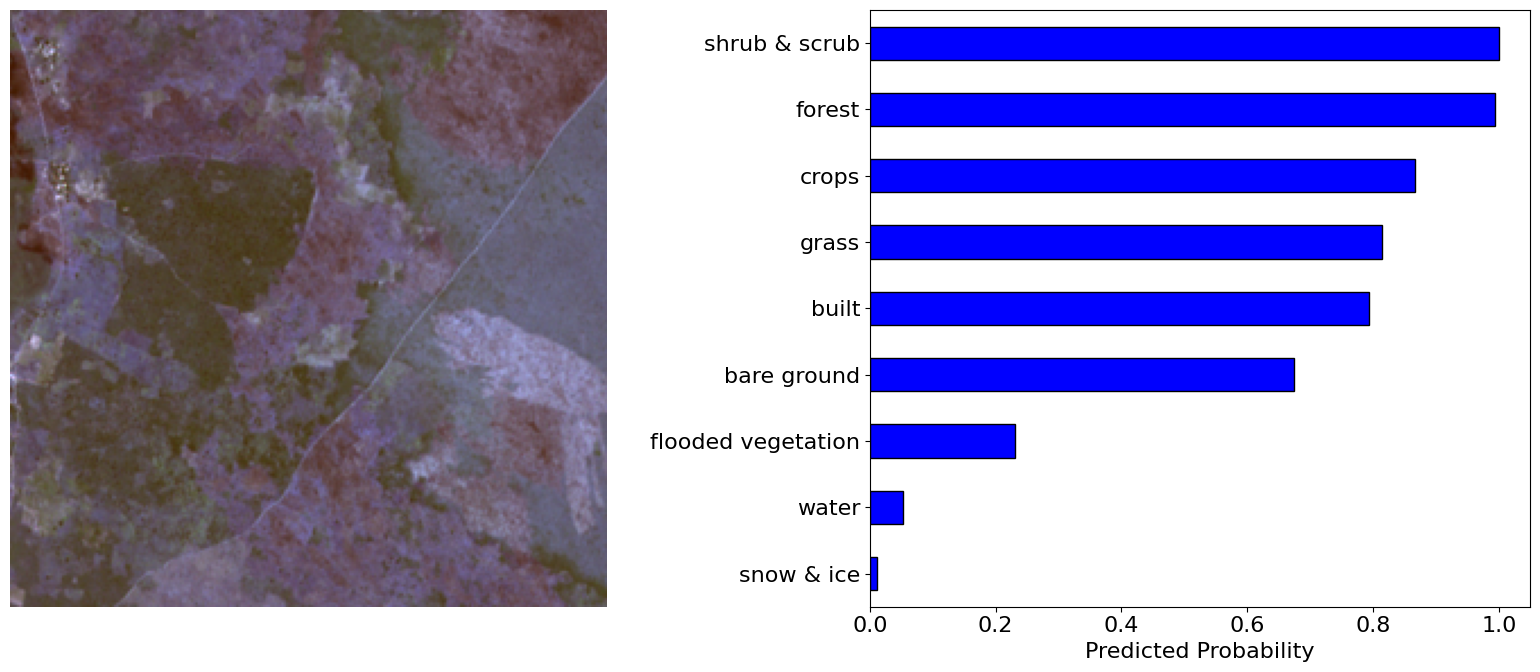

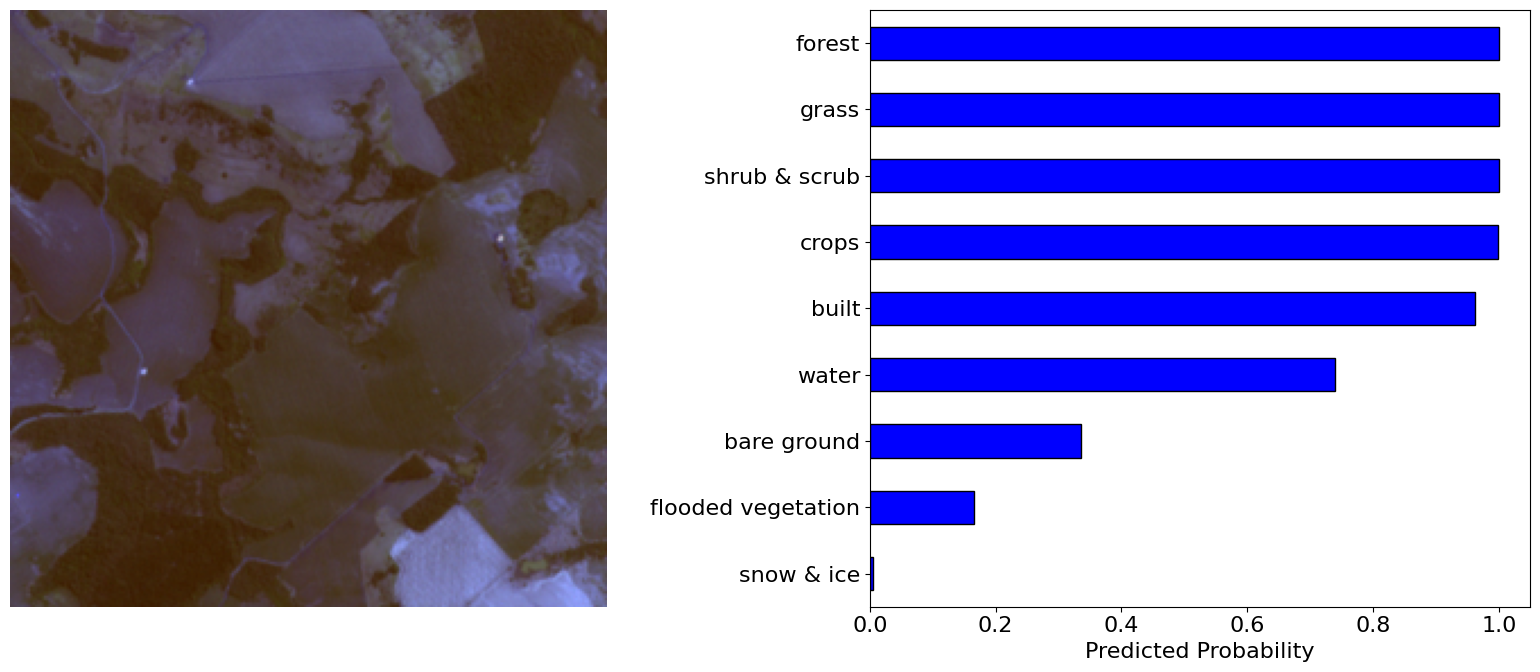

In [203]:
model_path = "/home/dragik/data/FAIR_EO/experiments/ssl4eo_s12_ml/checkpoint.pth.tar"
labels = ["water","forest","grass","flooded vegetation","crops","shrub & scrub","built","bare ground","snow & ice"]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/ssl4eo_s12_ml/",
    "label_file": "/home/dragik/data/FAIR_EO/ssl4eo_s12_ml/ssl4eo_multilabel.json",
    "imagery": "S2 L1C",
    "selection": "rgb",
    "csv_file": "/home/dragik/data/FAIR_EO/ssl4eo_s12_ml/ssl4eo_s12_ml_test.csv",
}

test_dataset = SSL4EOS12MLDataset(test_dataset_config)
len(test_dataset)

image = test_dataset[0][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_image(image, labels, transform)